# 03 - Forecasting

Loads the results and saved models produced by `scripts/train_models.py`, `scripts/generate_forecasts.py` and `scripts/generate_reports.py`; nothing is retrained here.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
from climate_yield.config import load_config
cfg = load_config()
import json
from IPython.display import Image
R = cfg.path('reports_dir')
figs = cfg.path('figures_dir')

In [2]:
summary = json.loads((R / 'training_summary.json').read_text())
print('mode:', summary['mode'], '| split:', summary['split'], '| best:', summary['best_model'])
pd.read_csv(R / 'model_comparison.csv').drop(columns='Best Params').round(3)

mode: full | split: {'train': '1991-2008', 'validation': '2009-2012', 'test': '2013-2016'} | best: RandomForest


,Model,Validation MAE,Holdout Validation MAE (2009-2012),Test MAE,Test RMSE,Test R2,Prediction Bias,Test MAPE %,Test MedAPE %,Test MAE log,Test MASE,Training Time (s),Prediction Time (s),Tuning Time (s)
0,Naive (last value),9569.901,10018.307,10660.110,29785.503,0.935,-817.867,12.550,5.260,0.118,1.216,0.151,0.022,0.668
1,DummyRegressor (mean growth),9662.018,10102.210,10716.602,29997.214,0.935,390.558,12.708,5.178,0.118,1.222,0.177,0.020,0.706
2,LinearRegression,9465.330,9880.832,10471.209,25914.698,0.951,-553.055,12.481,6.143,0.114,1.194,0.296,0.028,1.280
3,RandomForest,9155.404,9523.557,10008.504,26050.304,0.951,-522.374,12.038,5.533,0.109,1.141,12.916,0.158,959.503
4,XGBoost,9232.213,9566.139,10097.827,26605.322,0.949,-141.604,12.121,5.496,0.109,1.151,2.967,0.034,144.938
5,LightGBM,9241.199,9555.538,10035.548,26107.262,0.950,-318.179,12.082,5.441,0.109,1.144,2.158,0.077,144.254


In [3]:
pd.read_csv(R / 'feature_set_comparison.csv').round(3)

,feature_set,n_features,uses_same_year_climate,valid_forecast,cv_MAE,test_MAE,test_RMSE,test_R2,test_MedAPE_pct,test_Bias
0,history,11,False,True,9193.962,10055.463,25946.526,0.951,5.519,-996.800
1,forecast,23,False,True,9155.404,10008.504,26050.304,0.951,5.533,-522.374
2,conditional,32,True,False,9197.381,10013.167,26230.830,0.950,5.553,-587.062


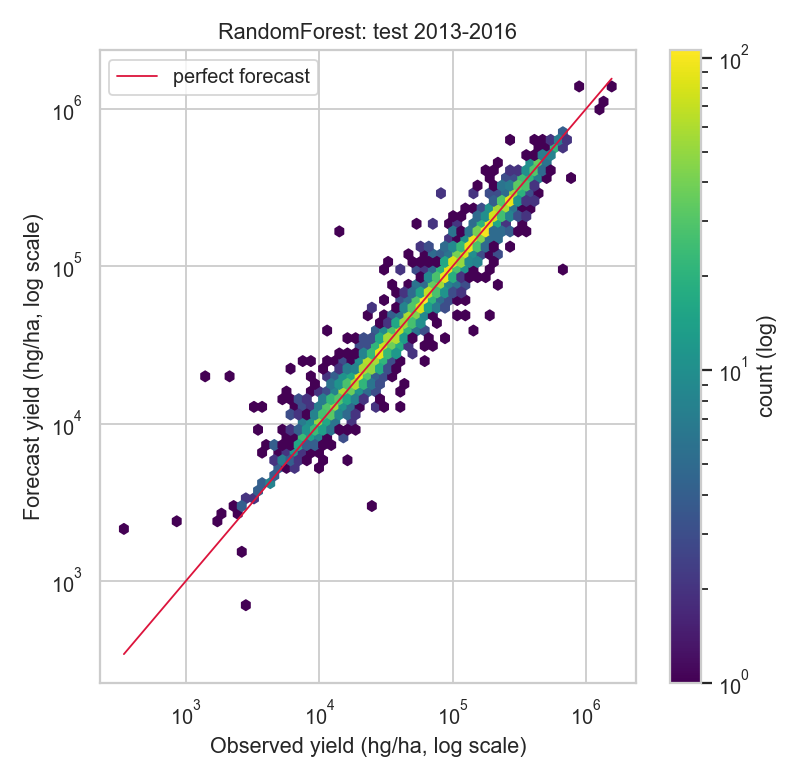

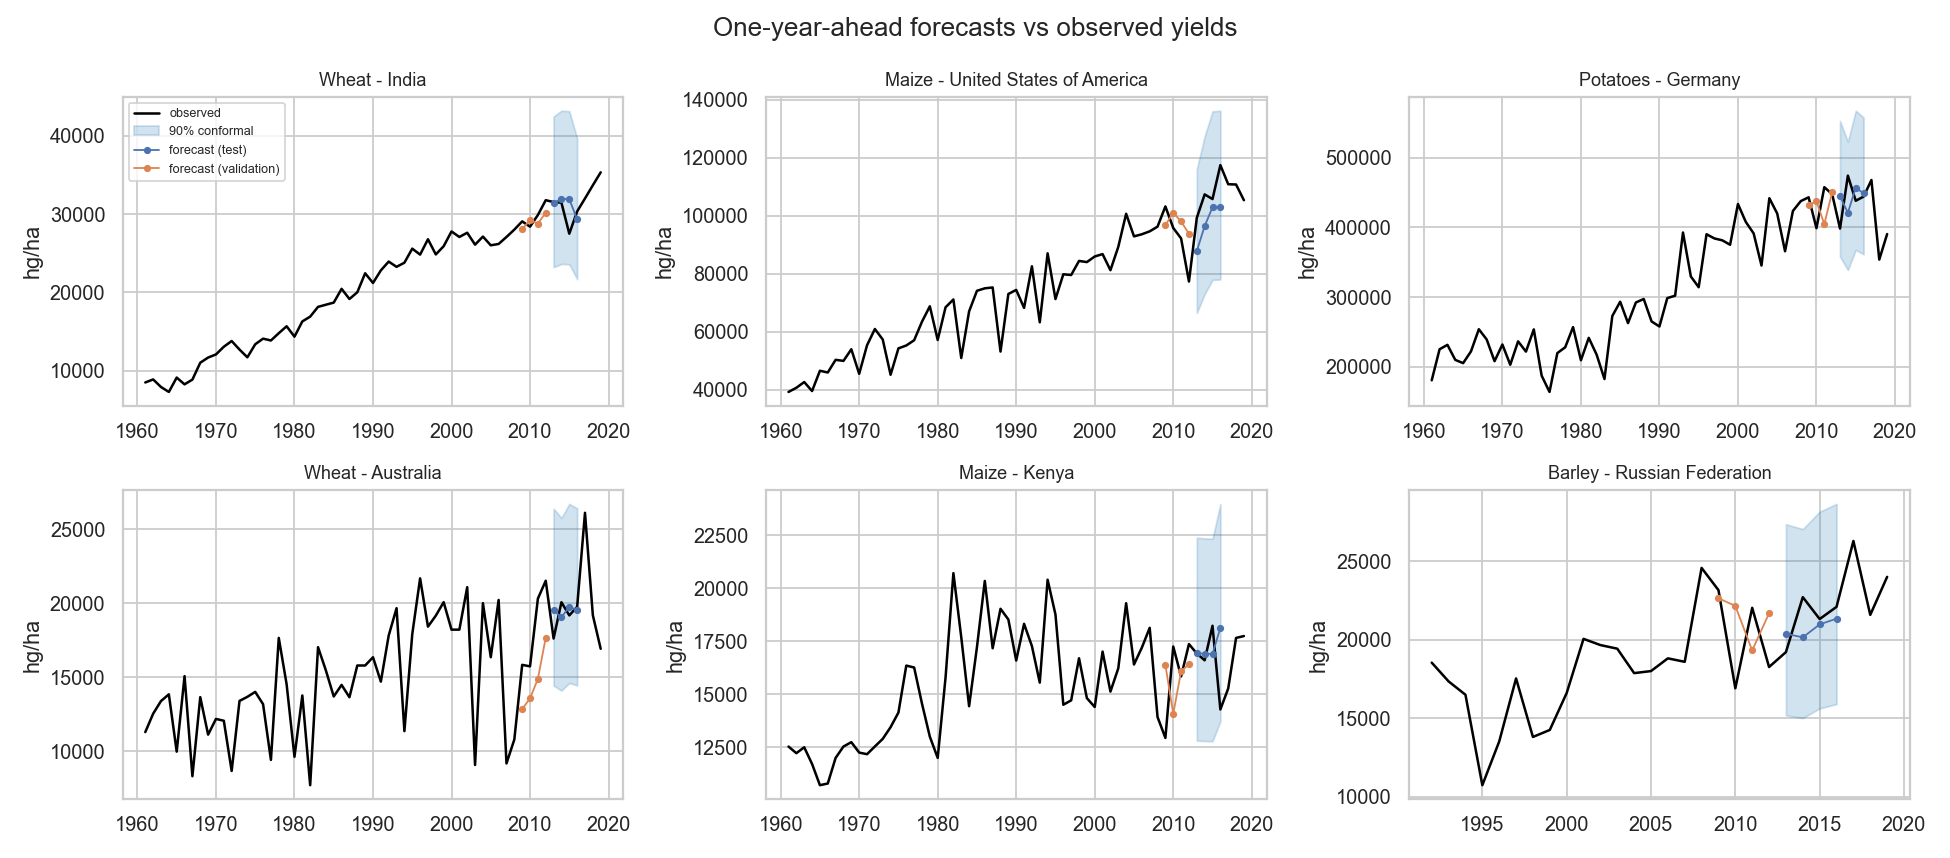

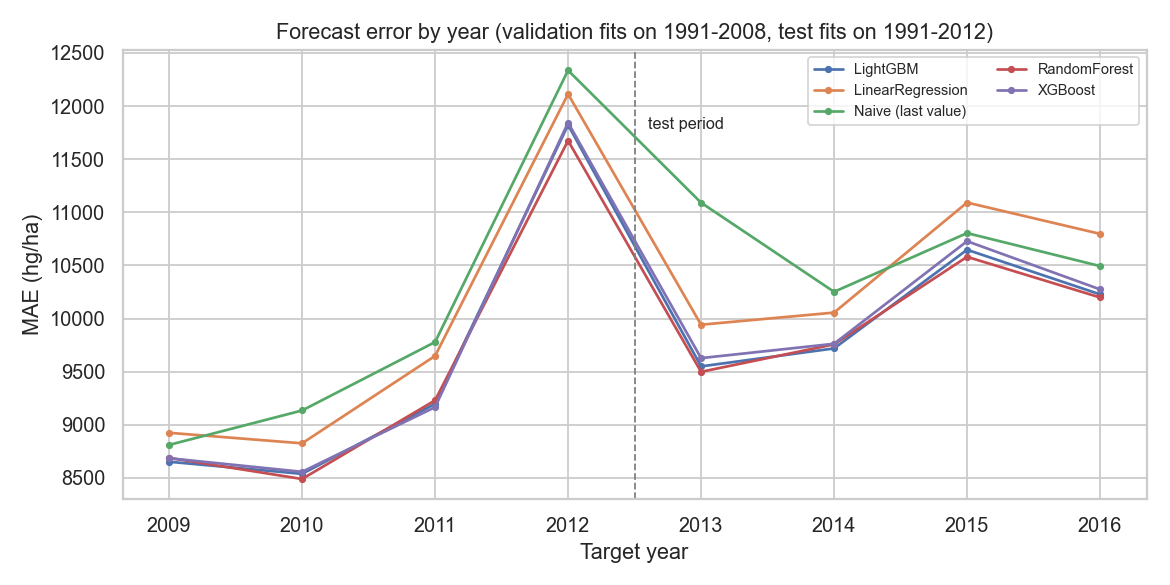

In [4]:
display(Image(filename=str(figs / 'actual_vs_predicted.png')))
display(Image(filename=str(figs / 'forecast_examples.png')))
display(Image(filename=str(figs / 'error_over_time.png')))

## Uncertainty

In [5]:
pd.read_csv(R / 'interval_coverage.csv').round(3)

,method,nominal_coverage,observed_coverage,mean_width_hg_ha,median_width_hg_ha,median_relative_width,n
0,per-crop (Mondrian),0.8,0.818,32422.179,20677.018,0.347,4905
1,pooled,0.8,0.813,36423.473,21031.704,0.347,4905
2,per-crop (Mondrian),0.9,0.903,52888.952,33453.891,0.549,4905
3,pooled,0.9,0.907,59138.932,34148.103,0.564,4905


## Reloading a saved model and forecasting

In [6]:
from climate_yield.pipeline import prepare_data
from climate_yield.predict import Forecaster, forecast_rows
data = prepare_data(cfg, save=False)
fc = Forecaster.load(cfg.path('models_dir') / 'deploy' / 'history_forecaster.joblib')
row = forecast_rows(data.features, 'France', 'Wheat', fc.bundle['forecast_year'])
pred, warnings = fc.predict_frame(row)
print(warnings)
pred.round(1)

[]


,pred_log_growth,yield_pred_hg_ha,lower_80,upper_80,lower_90,upper_90
20386,-0.1,73040.9,59410.3,89798.9,53269.9,100149.9


## Scenarios and explainability

In [7]:
pd.read_csv(R / 'scenario_results.csv').query("scenario != 'baseline'").groupby('scenario')['pct_change'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
scenario,,,,,,,,
hotter_drier,1226.0,-0.57,1.38,-7.58,-1.16,-0.28,0.34,2.49
hotter_wetter,1226.0,0.25,0.73,-2.46,-0.15,0.17,0.56,6.80
rain_+10pct,1226.0,0.13,0.68,-1.26,-0.19,0.00,0.24,7.06
rain_+20pct,1226.0,0.12,1.09,-2.56,-0.36,-0.03,0.33,9.61
rain_-10pct,1226.0,-0.35,0.81,-5.79,-0.61,-0.15,0.08,1.60
rain_-20pct,1226.0,-1.28,1.81,-10.34,-2.01,-0.69,-0.05,2.06
temp_+1C,1226.0,0.07,0.58,-4.62,-0.18,0.08,0.36,2.09
temp_+2C,1226.0,0.05,0.71,-5.59,-0.23,0.08,0.45,2.09


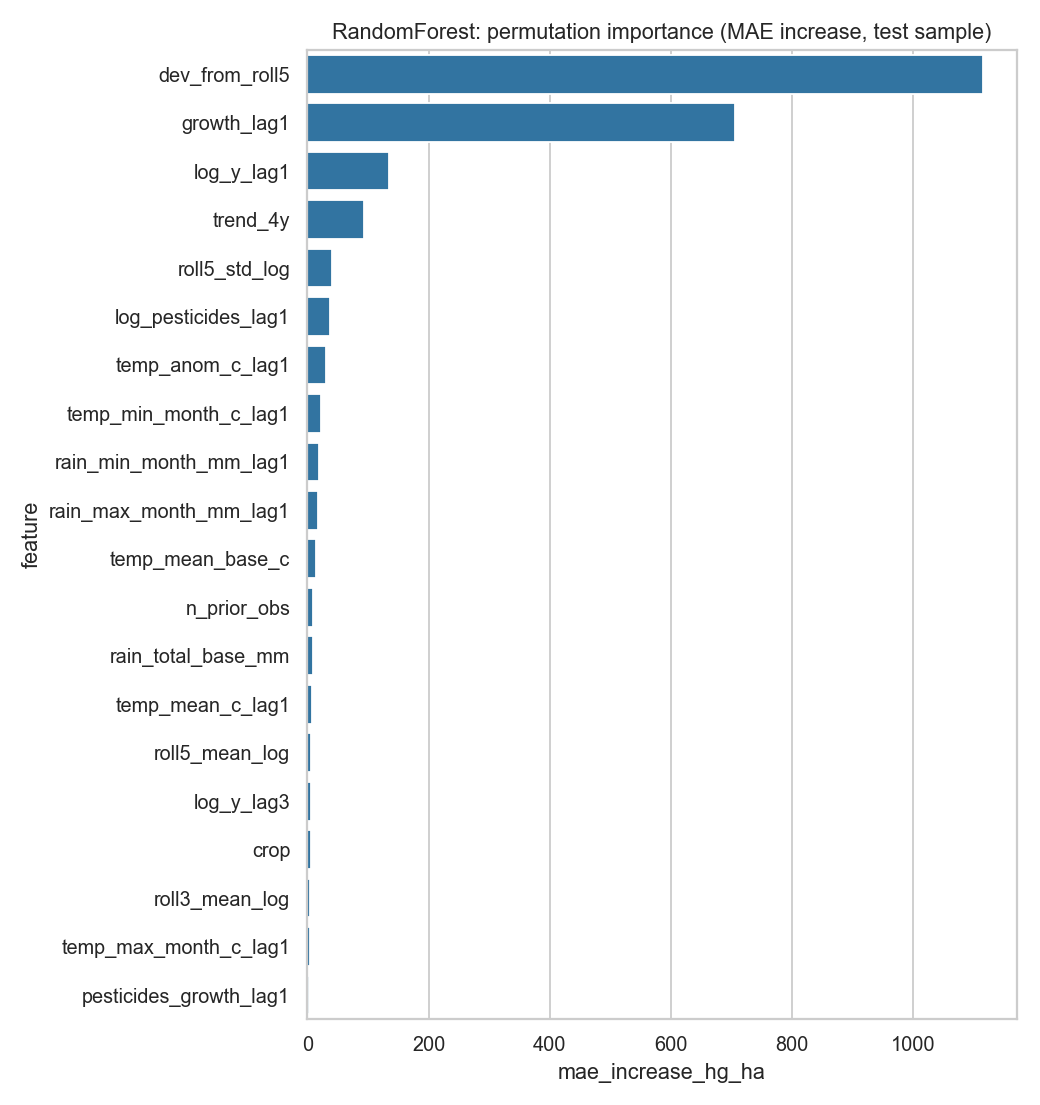

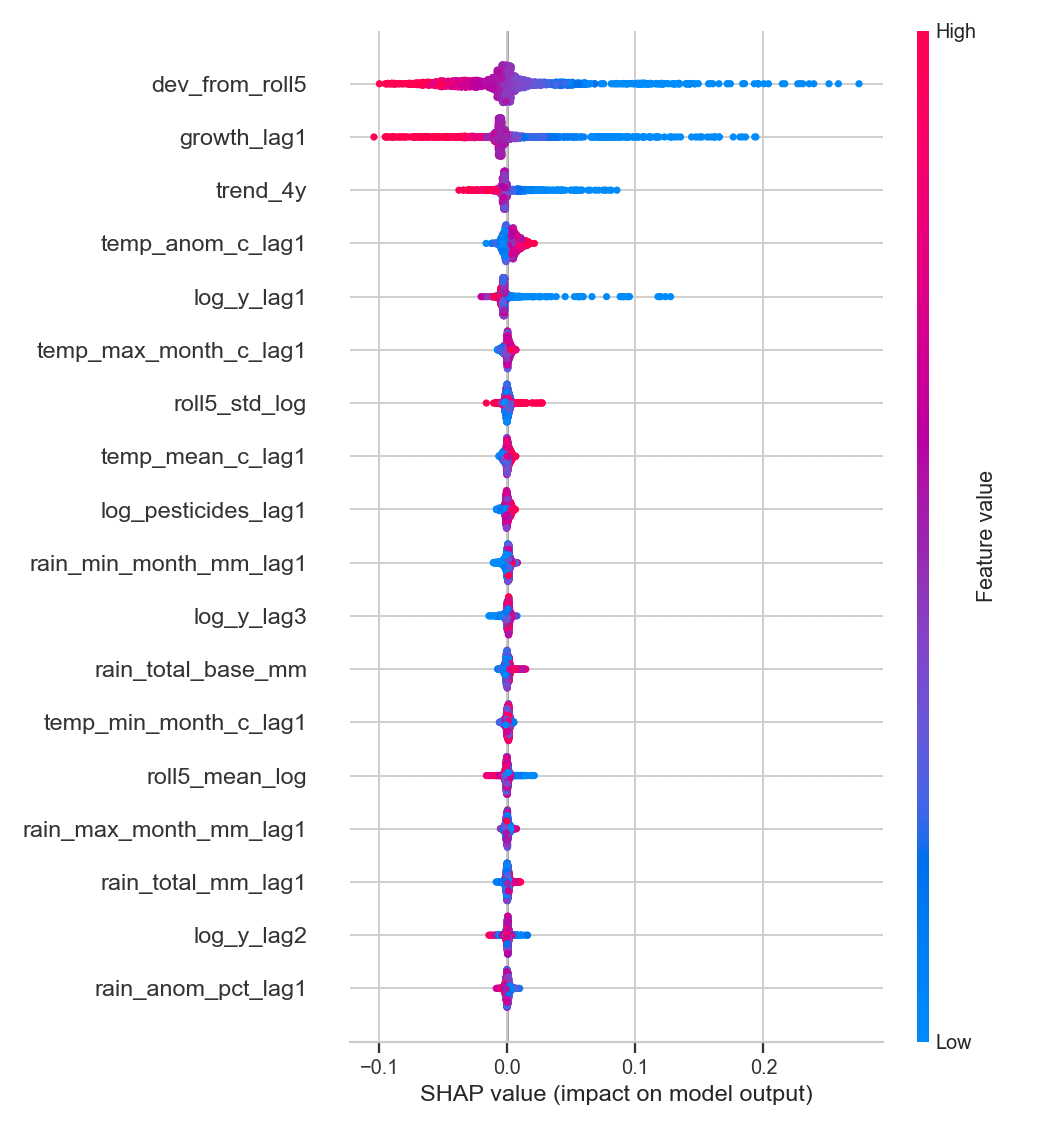

In [8]:
display(Image(filename=str(figs / 'permutation_importance.png')))
display(Image(filename=str(figs / 'shap_beeswarm.png')))